<a href="https://colab.research.google.com/github/ikwak2/4Dgradcam/blob/main/21_min/min_analysis250602.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

주제: 식욕 억제제 처방을 받은 환자들 중 객관적 and 주관적 후각 or 미각 장애 환자들은 얼마나 되며, 어떤 임상적 특징을 가지고 있을까?

1. Descriptive data: 실제 검사 상 후각, 미각 기능 이상을 보이는 환자들에 대하여 (통계량 뽑을 때 참여 취소 등 제외여부 확인, 참여취소, F/U loss 등)
1-1. 객관적 검사상 후각 기능 저하를 보인 경우와 정상인 경우에 대하여 유의한 factor 가 있는지 통계 분석
-> 그루핑을 BX, BY로 하는 것일지? 후각은 괜찮은데, BY의 경우 미각 이상 환자는 1명밖에 없어서 미각 이상 관련 분석은 샘플 수 부족으로 어려움.. (기술통계 table 작성은 가능하지만, 통계적 비교는 불가능)


2. VAS score 1점 이상 기준으로 주관적 후각 이상을 호소한 경우 (파란 글씨 표기 환자 )에 대한 descriptive data
 (나머지 검사 항목에 대해서)
2-1. VAS score 1 점 이상 기준 (파란 글씨 표기 환자)으로 주관적 후각 이상을 호소한 경우와 주관적 후각 이상이 없는 환자에 대하여 유의한 factor 가 있는지 통계 분석

3. 후각 VAS score (BW 열) 와 비례 혹은 반비례하는 임상적 인자가 있는지 통계 분석
(VAS score 가 높을수록 주관적 후각 불편감이 있는 것)
	종속변수를 VAS 로 두고 다중선형회귀 고려
	TDI score 나 W행도 살펴보기

4. Parosmia 만 따로 분석?? (BV, 이상한 냄새를 느끼는 주관적 지표)  
=> 이건 각각 통계량 뽑을 때 점수분포 살펴봄  

In [1]:
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
system("gdown --id 17aqy06YOtRF7eGsxcqs1JDnT9Ldcbmdp")
data = read_csv("min250520.csv")

Rows: 70 Columns: 77
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (8): id_num, reginum, weak, Sex, Smoking, medication, nose_function, ta...
dbl (68): ENTdate, Age, Height, weight, BMI, SM, bodyfat, BMR, waist_circum,...
lgl  (1): etc

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
data[1:3,]

id_num,ENTdate,reginum,weak,Sex,Age,Smoking,Height,weight,BMI,⋯,a3-P,a5-P,sumQOD-P,P,sumVAS,nose_function,taste_function,Phentermine_Naltrexone,Orlistat,Liraglutide_Semaglutide
<chr>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
OOG1,20240715,00897871,NA,F,45,none,165.0,64.4,23.7,⋯,2,0,7,58.33333,0,normosmia,normal,1,1,0
OOG2,20240715,01724462,NA,F,48,none,156.6,58.9,24.0,⋯,0,0,0,0.00000,0,normosmia,normal,1,1,0
OOG3,20240715,01722868,NA,M,28,none,173.2,98.1,32.7,⋯,0,0,0,0.00000,0,normosmia,normal,1,1,0


In [4]:
# data[,'BMI'] 행의 값이 23미만: 정상 (1)
# - 23이상, 25미만: 과체중 (2)
# - 25이상, 30미만: 1단계 비만 (3)
# - 30이상, 35미만: 2단계 비만 (4)
# - 35이상 : 3단계 비만 (5)  으로 코딩해줘

data <- data |>
  mutate(BMI_category = case_when(
    BMI < 23 ~ 1,
    BMI >= 23 & BMI < 25 ~ 2,
    BMI >= 25 & BMI < 30 ~ 3,
    BMI >= 30 & BMI < 35 ~ 4,
    BMI >= 35 ~ 5
  ))

data[1:3, c('BMI', 'BMI_category')]

BMI,BMI_category
<dbl>,<dbl>
23.7,2
24.0,2
32.7,4


In [5]:
# BMI_category2 는 '- 23미만: 정상 (1)
# - 23이상, 25미만: 과체중 (2)
# - 25이상, 비만 (3) 로 만들어줘

data <- data |>
  mutate(BMI_category2 = case_when(
    BMI < 23 ~ 1,
    BMI >= 23 & BMI < 25 ~ 2,
    BMI >= 25 ~ 3
  ))

data[1:3, c('BMI', 'BMI_category', 'BMI_category2')]

BMI,BMI_category,BMI_category2
<dbl>,<dbl>,<dbl>
23.7,2,2
24.0,2,2
32.7,4,3


In [6]:
# BMI_category2 는 '- 23미만: 정상 (1)
# - 23이상, 25미만: 과체중 (2)
# - 25이상, 비만 (3) 로 만들어줘

data <- data |>
  mutate(BMI_category3 = case_when(
    BMI < 25 ~ 1,
    BMI >= 25 ~ 2
  ))

data[1:3, c('BMI', 'BMI_category', 'BMI_category2', 'BMI_category3')]

BMI,BMI_category,BMI_category2,BMI_category3
<dbl>,<dbl>,<dbl>,<dbl>
23.7,2,2,1
24.0,2,2,1
32.7,4,3,2


In [7]:
colnames(data)

[1] "id_num"                  "ENTdate"                
 [3] "reginum"                 "weak"                   
 [5] "Sex"                     "Age"                    
 [7] "Smoking"                 "Height"                 
 [9] "weight"                  "BMI"                    
[11] "SM"                      "bodyfat"                
[13] "BMR"                     "waist_circum"           
[15] "Threshold"               "Discrimination"         
[17] "Identification"          "TDI"                    
[19] "tasteThreshold"          "tasteIdentification"    
[21] "WBC"                     "hs-CRP"                 
[23] "fasting_glucose"         "uric_acid"              
[25] "AST"                     "ALT"                    
[27] "insulin"                 "T_cholesterol"          
[29] "triglyceride"            "HDLcholesterol"         
[31] "LDLcholesterol"          "cortisol"               
[33] "freeT4"                  "TSH"                    
[35] "medication"              "etc"                    
[37] "a1-LQ"                   "a4-LQ"                  
[39] "a11-LQ"                  "a13-LQ"                 
[41] "a15-LQ"                  "a19-LQ"                 
[43] "a22-LQ"                  "a26-LQ"                 
[45] "a27-LQ"                  "a28-LQ"                 
[47] "a33-LQ"                  "a34-LQ"                 
[49] "a37-LQ"                  "a39-LQ"                 
[51] "a42-LQ"                  "a49-LQ"                 
[53] "a50-LQ"                  "a32-LQ"                 
[55] "a35-LQ"                  "sumQOD-LQ"              
[57] "LQ"                      "a14-S"                  
[59] "a17-S"                   "a23-S"                  
[61] "a31-S"                   "a36-S"                  
[63] "a48-S"                   "sumQOD-S"               
[65] "S"                       "a1-P"                   
[67] "a2-P"                    "a3-P"                   
[69] "a5-P"                    "sumQOD-P"               
[71] "P"                       "sumVAS"                 
[73] "nose_function"           "taste_function"         
[75] "Phentermine_Naltrexone"  "Orlistat"               
[77] "Liraglutide_Semaglutide" "BMI_category"           
[79] "BMI_category2"           "BMI_category3"

In [8]:

data <- data |>
  mutate(Obesity_wc = case_when(
    Sex == 'F' & waist_circum >= 85 ~ 1,
    Sex == 'F' & waist_circum < 85 ~ 0,
    Sex == 'M' & waist_circum >= 90 ~ 1,
    Sex == 'M' & waist_circum < 90 ~ 0
  ))

data[1:3, c('Sex', 'waist_circum', 'Obesity_wc')]

Sex,waist_circum,Obesity_wc
<chr>,<dbl>,<dbl>
F,86.7,1
F,77.6,0
M,109.9,1


In [9]:
colnames(data)

[1] "id_num"                  "ENTdate"                
 [3] "reginum"                 "weak"                   
 [5] "Sex"                     "Age"                    
 [7] "Smoking"                 "Height"                 
 [9] "weight"                  "BMI"                    
[11] "SM"                      "bodyfat"                
[13] "BMR"                     "waist_circum"           
[15] "Threshold"               "Discrimination"         
[17] "Identification"          "TDI"                    
[19] "tasteThreshold"          "tasteIdentification"    
[21] "WBC"                     "hs-CRP"                 
[23] "fasting_glucose"         "uric_acid"              
[25] "AST"                     "ALT"                    
[27] "insulin"                 "T_cholesterol"          
[29] "triglyceride"            "HDLcholesterol"         
[31] "LDLcholesterol"          "cortisol"               
[33] "freeT4"                  "TSH"                    
[35] "medication"              "etc"                    
[37] "a1-LQ"                   "a4-LQ"                  
[39] "a11-LQ"                  "a13-LQ"                 
[41] "a15-LQ"                  "a19-LQ"                 
[43] "a22-LQ"                  "a26-LQ"                 
[45] "a27-LQ"                  "a28-LQ"                 
[47] "a33-LQ"                  "a34-LQ"                 
[49] "a37-LQ"                  "a39-LQ"                 
[51] "a42-LQ"                  "a49-LQ"                 
[53] "a50-LQ"                  "a32-LQ"                 
[55] "a35-LQ"                  "sumQOD-LQ"              
[57] "LQ"                      "a14-S"                  
[59] "a17-S"                   "a23-S"                  
[61] "a31-S"                   "a36-S"                  
[63] "a48-S"                   "sumQOD-S"               
[65] "S"                       "a1-P"                   
[67] "a2-P"                    "a3-P"                   
[69] "a5-P"                    "sumQOD-P"               
[71] "P"                       "sumVAS"                 
[73] "nose_function"           "taste_function"         
[75] "Phentermine_Naltrexone"  "Orlistat"               
[77] "Liraglutide_Semaglutide" "BMI_category"           
[79] "BMI_category2"           "BMI_category3"          
[81] "Obesity_wc"

In [10]:
# prompt: Obesity_bf 변수를 만들건데, Sex 가 'F'인 경우 bodyfat 이 30이상이면 1 아니면 0, Sex가 'M' 인 경우 bodyfat이 25 이상이면 1 아니면 0

data <- data |>
  mutate(Obesity_bf = case_when(
    Sex == 'F' & bodyfat >= 30 ~ 1,
    Sex == 'F' & bodyfat < 30 ~ 0,
    Sex == 'M' & bodyfat >= 25 ~ 1,
    Sex == 'M' & bodyfat < 25 ~ 0
  ))

data[1:3, c('Sex', 'bodyfat', 'Obesity_bf')]

Sex,bodyfat,Obesity_bf
<chr>,<dbl>,<dbl>
F,38.3,1
F,30.1,1
M,39.0,1


In [11]:
dim(data)

[1] 70 82

In [12]:
70-65

[1] 5

In [13]:
sum(data$Obesity_bf)

[1] 65

In [14]:
install.packages("moonBook")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘insight’, ‘datawizard’, ‘sjlabelled’, ‘nortest’, ‘sjmisc’




In [15]:
library(moonBook)

In [16]:
colnames(data)

[1] "id_num"                  "ENTdate"                
 [3] "reginum"                 "weak"                   
 [5] "Sex"                     "Age"                    
 [7] "Smoking"                 "Height"                 
 [9] "weight"                  "BMI"                    
[11] "SM"                      "bodyfat"                
[13] "BMR"                     "waist_circum"           
[15] "Threshold"               "Discrimination"         
[17] "Identification"          "TDI"                    
[19] "tasteThreshold"          "tasteIdentification"    
[21] "WBC"                     "hs-CRP"                 
[23] "fasting_glucose"         "uric_acid"              
[25] "AST"                     "ALT"                    
[27] "insulin"                 "T_cholesterol"          
[29] "triglyceride"            "HDLcholesterol"         
[31] "LDLcholesterol"          "cortisol"               
[33] "freeT4"                  "TSH"                    
[35] "medication"              "etc"                    
[37] "a1-LQ"                   "a4-LQ"                  
[39] "a11-LQ"                  "a13-LQ"                 
[41] "a15-LQ"                  "a19-LQ"                 
[43] "a22-LQ"                  "a26-LQ"                 
[45] "a27-LQ"                  "a28-LQ"                 
[47] "a33-LQ"                  "a34-LQ"                 
[49] "a37-LQ"                  "a39-LQ"                 
[51] "a42-LQ"                  "a49-LQ"                 
[53] "a50-LQ"                  "a32-LQ"                 
[55] "a35-LQ"                  "sumQOD-LQ"              
[57] "LQ"                      "a14-S"                  
[59] "a17-S"                   "a23-S"                  
[61] "a31-S"                   "a36-S"                  
[63] "a48-S"                   "sumQOD-S"               
[65] "S"                       "a1-P"                   
[67] "a2-P"                    "a3-P"                   
[69] "a5-P"                    "sumQOD-P"               
[71] "P"                       "sumVAS"                 
[73] "nose_function"           "taste_function"         
[75] "Phentermine_Naltrexone"  "Orlistat"               
[77] "Liraglutide_Semaglutide" "BMI_category"           
[79] "BMI_category2"           "BMI_category3"          
[81] "Obesity_wc"              "Obesity_bf"

In [17]:
data$subjective_nose = as.numeric(data[,'sumVAS'] >= 1)
data$Smoking <- as.numeric(ifelse(data$Smoking == 'none', 0, data$Smoking))

In [18]:
data$parosmia = data$P >=1

In [19]:
data$subjective_nose

[1] 0 0 0 0 1 0 0 0 0 0 1 0 1 0 0 0 1 0 0 1 1 0 0 1 1 1 0 1 0 1 1 1 0 1 1 1 1 1
[39] 0 0 1 0 0 1 0 1 1 0 0 1 0 1 0 0 1 0 1 1 1 1 1 0 0 0 0 0 1 1 1 1

### 내용

1. 대상자 중 실제 후각 이상을 보인 경우는 적었다.
2. 객관적 검사상 후각 기능 결과와 유의한 연관성을 보이는 항목은 ---- 였다.
(이전의 연구 결과와 유사점, 차이점, 약제 차이 없었음)
3. 주관적 후각 이상과 연관성을 보이는 항목은 ---였다.
(주관적 이상과 객관적 이상을 보이는 경우를 나누어 통합적으로 분석한 연구가 매우 드물다)
4. parosmia 를 호소한 특징적인 경우는  ---  와 연관성을 보였다.
(parosmia 항목도 특별히 고려해야 한다)
5. ----- 인 경우 후각에 대한 evaluation 을 적극적으로 고려해야 하며, 주관적 후각 이상 및 parosmia 도 고려 대상에 포함시켜 통합적인 evaluation  필요하다.

(Supplementary) Figure 1: Flowchart of participant enrollment in the prospective study


Table 1. Characteristics of enrolled subjects according to psychophysical olfactory function test results (Normosmia vs. Hyposmia). (연속형 범주형 모두 포함하는 table 하나로)
Figure 2. Characteristics significantly associated with the results of psychophysical olfactory function test (표 대신 그림으로 가능하다면)
Table 2. Characteristics of enrolled subjects according to subjective olfactory discomfort (연속형 범주형 모두 포함하는 table 하나로)
Figure 3. Characteristics significantly associated with subjective olfactory discomfort (표 대신 그림으로 가능하다면)
Table 3. Characteristics of enrolled subjects according to the presence or absence of subjective parosmia
Figure 4. Characteristics significantly associated with subjective parosmia (표 대신 그림으로 가능하다면)



## Descriptive data: 실제 검사 상 후각, 미각 기능 이상을 보이는 환자들에 대하여

###1-1. 객관적 검사상 후각 기능 저하를 보인 경우와 정상인 경우에 대하여 유의한 factor 가 있는지 통계 분석

In [21]:
mytable(nose_function ~ Phentermine_Naltrexone + Orlistat + Liraglutide_Semaglutide+subjective_nose + P, data=data, digits=2, catMethod=0)


        Descriptive Statistics by 'nose_function'        
—————————————————————————————————————————————————————————— 
                           hyposmia      normosmia     p  
                             (N=5)        (N=65)    
—————————————————————————————————————————————————————————— 
 Phentermine_Naltrexone                              0.375
   - 0                    1 (20.00%)     5 (7.81%)        
   - 1                    4 (80.00%)    59 (92.19%)       
 Orlistat                                            1.000
   - 0                     0 ( 0.0%)     1 (1.54%)        
   - 1                    5 (100.00%)   64 (98.46%)       
 Liraglutide_Semaglutide                             0.508
   - 0                    4 (80.00%)    57 (87.69%)       
   - 1                    1 (20.00%)    8 (12.31%)        
 subjective_nose                                     0.358
   - 0                    4 (80.00%)    32 (49.23%)       
   - 1                    1 (20.00%)    33 (50.77%)       
 

VAS 가 1보다 큰 주관적 후각이상이 후각이상 그룹에서는 오히려 적었고, 정상인 그룹은 VAS 1이상 분포가 반반..

In [22]:
str(data$Identification)

 num [1:70] 12 11 12 12 11 12 11 12 12 12 ...


In [23]:
install.packages("tableone")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘gtools’, ‘minqa’, ‘numDeriv’, ‘mitools’, ‘RcppArmadillo’, ‘proxy’, ‘gdata’, ‘survey’, ‘e1071’, ‘zoo’, ‘gmodels’, ‘labelled’




In [24]:
library(tableone)


In [25]:
CreateTableOne(vars = c("Age", "Height", "weight", "BMI", "SM", "bodyfat", "BMR", "waist_circum", "Threshold", "Discrimination", "Identification", "TDI", "tasteThreshold", "tasteIdentification" , "WBC", "hs-CRP", "fasting_glucose", "uric_acid", "AST", "ALT", "insulin", "T_cholesterol", "triglyceride", "HDLcholesterol", "LDLcholesterol", "cortisol", "freeT4", "TSH", "P"), strata = "nose_function", data = data)

                                 Stratified by nose_function
                                  hyposmia         normosmia        p      test
  n                                     5               65                     
  Age (mean (SD))                   46.60 (15.82)    41.25 (10.50)   0.293     
  Height (mean (SD))               158.76 (10.53)   163.30 (7.77)    0.223     
  weight (mean (SD))                89.64 (19.24)    80.29 (19.99)   0.316     
  BMI (mean (SD))                   35.36 (5.47)     29.89 (5.70)    0.042     
  SM (mean (SD))                    29.54 (9.17)     27.05 (6.30)    0.412     
  bodyfat (mean (SD))               41.58 (6.17)     38.10 (6.28)    0.236     
  BMR (mean (SD))                 1506.00 (310.92) 1430.58 (225.81)  0.485     
  waist_circum (mean (SD))         107.68 (11.61)    97.09 (14.63)   0.120     
  Threshold (mean (SD))              2.80 (0.91)      4.02 (1.01)    0.011     
  Discrimination (mean (SD))         6.80 (1.30)      9.14 

연속형 변수

In [26]:
CreateTableOne(vars = c("Age", "Height", "weight", "BMI", "SM", "bodyfat", "BMR", "waist_circum", "Threshold", "Discrimination", "Identification", "TDI", "tasteThreshold", "tasteIdentification" , "WBC", "hs-CRP", "fasting_glucose", "uric_acid", "AST", "ALT", "insulin", "T_cholesterol", "triglyceride", "HDLcholesterol", "LDLcholesterol", "cortisol", "freeT4", "TSH", "P"), strata = "nose_function", data = data)

                                 Stratified by nose_function
                                  hyposmia         normosmia        p      test
  n                                     5               65                     
  Age (mean (SD))                   46.60 (15.82)    41.25 (10.50)   0.293     
  Height (mean (SD))               158.76 (10.53)   163.30 (7.77)    0.223     
  weight (mean (SD))                89.64 (19.24)    80.29 (19.99)   0.316     
  BMI (mean (SD))                   35.36 (5.47)     29.89 (5.70)    0.042     
  SM (mean (SD))                    29.54 (9.17)     27.05 (6.30)    0.412     
  bodyfat (mean (SD))               41.58 (6.17)     38.10 (6.28)    0.236     
  BMR (mean (SD))                 1506.00 (310.92) 1430.58 (225.81)  0.485     
  waist_circum (mean (SD))         107.68 (11.61)    97.09 (14.63)   0.120     
  Threshold (mean (SD))              2.80 (0.91)      4.02 (1.01)    0.011     
  Discrimination (mean (SD))         6.80 (1.30)      9.14 

In [27]:
CreateTableOne(vars = c("Age", "Height", "weight", "BMI", "SM", "bodyfat", "BMR", "waist_circum", "Threshold", "Discrimination", "Identification", "TDI", "tasteThreshold", "tasteIdentification" , "WBC", "hs-CRP", "fasting_glucose", "uric_acid", "AST", "ALT", "insulin", "T_cholesterol", "triglyceride", "HDLcholesterol", "LDLcholesterol", "cortisol", "freeT4", "TSH" ), strata = "parosmia", data = data)

                                 Stratified by parosmia
                                  FALSE            TRUE             p      test
  n                                    20               50                     
  Age (mean (SD))                   40.45 (12.43)    42.10 (10.31)   0.571     
  Height (mean (SD))               162.85 (7.68)    163.03 (8.18)    0.935     
  weight (mean (SD))                82.47 (19.29)    80.35 (20.37)   0.691     
  BMI (mean (SD))                   30.89 (5.62)     30.04 (5.93)    0.583     
  SM (mean (SD))                    27.22 (5.86)     27.23 (6.78)    0.996     
  bodyfat (mean (SD))               39.44 (6.39)     37.90 (6.27)    0.359     
  BMR (mean (SD))                 1435.05 (208.48) 1436.34 (241.20)  0.983     
  waist_circum (mean (SD))          99.27 (15.34)    97.28 (14.45)   0.611     
  Threshold (mean (SD))              4.40 (1.13)      3.74 (0.95)    0.016     
  Discrimination (mean (SD))         8.75 (1.41)      9.06 (1.41

In [28]:
mytable(parosmia ~ Sex + Smoking + BMI_category + BMI_category2 + Phentermine_Naltrexone + Orlistat + Liraglutide_Semaglutide+subjective_nose + nose_function  , data=data, digits=2, catMethod=0)


         Descriptive Statistics by 'parosmia'         
——————————————————————————————————————————————————————— 
                            FALSE        TRUE       p  
                            (N=20)      (N=50)   
——————————————————————————————————————————————————————— 
 Sex                                              1.000
   - F                   16 (80.00%)  39 (78.00%)      
   - M                    4 (20.00%)  11 (22.00%)      
 Smoking                                          1.000
   - 0                   19 (95.00%)  47 (94.00%)      
   - 1                    1 (5.00%)    3 (6.00%)       
 BMI_category                                     0.672
   - 1                     0 ( 0.0%)   4 (8.00%)       
   - 2                    3 (15.00%)   4 (8.00%)       
   - 3                    7 (35.00%)  19 (38.00%)      
   - 4                    6 (30.00%)  16 (32.00%)      
   - 5                    4 (20.00%)  7 (14.00%)       
 BMI_category2                                    0.

In [29]:
mytable(nose_function ~ Sex + Smoking + BMI_category + BMI_category2 + Phentermine_Naltrexone + Orlistat + Liraglutide_Semaglutide+subjective_nose  , data=data, digits=2, catMethod=0)


      Descriptive Statistics by 'nose_function'      
—————————————————————————————————————————————————————— 
                          hyposmia    normosmia    p  
                            (N=5)      (N=65)   
—————————————————————————————————————————————————————— 
 Sex                                             0.290
   - F                   3 (60.00%)  52 (80.00%)      
   - M                   2 (40.00%)  13 (20.00%)      
 Smoking                                         1.000
   - 0                   5 (100.00%) 61 (93.85%)      
   - 1                    0 ( 0.0%)   4 (6.15%)       
 BMI_category                                    0.560
   - 1                    0 ( 0.0%)   4 (6.15%)       
   - 2                    0 ( 0.0%)  7 (10.77%)       
   - 3                   1 (20.00%)  25 (38.46%)      
   - 4                   2 (40.00%)  20 (30.77%)      
   - 5                   2 (40.00%)  9 (13.85%)       
 BMI_category2                                   1.000
   - 1        

2. VAS score 1점 이상 기준으로 주관적 후각 이상을 호소한 경우 (파란 글씨 표기 환자 )에 대한 descriptive data
 (나머지 검사 항목에 대해서)
2-1. VAS score 1 점 이상 기준 (파란 글씨 표기 환자)으로 주관적 후각 이상을 호소한 경우와 주관적 후각 이상이 없는 환자에 대하여 유의한 factor 가 있는지 통계 분석

In [ ]:
CreateTableOne(vars = c("Age", "Height", "weight", "BMI", "SM", "bodyfat", "BMR", "waist_circum", "Threshold", "Discrimination", "Identification", "TDI", "tasteThreshold", "tasteIdentification" , "WBC", "hs-CRP", "fasting_glucose", "uric_acid", "AST", "ALT", "insulin", "T_cholesterol", "triglyceride", "HDLcholesterol", "LDLcholesterol", "cortisol", "freeT4", "TSH", "P"), strata = "subjective_nose", data = data)

                                 Stratified by subjective_nose
                                  0                1                p      test
  n                                    36               34                     
  Age (mean (SD))                   38.86 (10.55)    44.56 (10.62)   0.028     
  Height (mean (SD))               164.01 (7.53)    161.89 (8.42)    0.272     
  weight (mean (SD))                82.38 (22.33)    79.45 (17.29)   0.543     
  BMI (mean (SD))                   30.31 (6.02)     30.25 (5.69)    0.964     
  SM (mean (SD))                    27.80 (6.72)     26.61 (6.27)    0.448     
  bodyfat (mean (SD))               38.19 (5.46)     38.50 (7.16)    0.839     
  BMR (mean (SD))                 1455.25 (240.37) 1415.56 (222.03)  0.476     
  waist_circum (mean (SD))          98.00 (14.79)    97.69 (14.68)   0.931     
  Threshold (mean (SD))              4.14 (1.20)      3.71 (0.81)    0.083     
  Discrimination (mean (SD))         8.81 (1.33)      9.1

In [ ]:
mytable(subjective_nose ~ Sex + Smoking + BMI_category + BMI_category2 + Phentermine_Naltrexone + Orlistat + Liraglutide_Semaglutide+nose_function  , data=data, digits=2, catMethod=0)


      Descriptive Statistics by 'subjective_nose'     
——————————————————————————————————————————————————————— 
                              0            1        p  
                            (N=36)      (N=34)   
——————————————————————————————————————————————————————— 
 Sex                                              0.647
   - F                   27 (75.00%)  28 (82.35%)      
   - M                    9 (25.00%)  6 (17.65%)       
 Smoking                                          0.615
   - 0                   33 (91.67%)  33 (97.06%)      
   - 1                    3 (8.33%)    1 (2.94%)       
 BMI_category                                     0.780
   - 1                    1 (2.78%)    3 (8.82%)       
   - 2                    4 (11.11%)   3 (8.82%)       
   - 3                   15 (41.67%)  11 (32.35%)      
   - 4                   10 (27.78%)  12 (35.29%)      
   - 5                    6 (16.67%)  5 (14.71%)       
 BMI_category2                                    0.

BMI 의 경우 0 인게 생겨서, 카테고리할 경우 분석이 안될 수 있음

In [ ]:
CreateTableOne(vars = c("Age", "Height", "weight", "BMI", "SM", "bodyfat", "BMR", "waist_circum", "Threshold", "Discrimination", "Identification", "TDI", "tasteThreshold", "tasteIdentification" , "WBC", "hs-CRP", "fasting_glucose", "uric_acid", "AST", "ALT", "insulin", "T_cholesterol", "triglyceride", "HDLcholesterol", "LDLcholesterol", "cortisol", "freeT4", "TSH", "subjective_nose"), strata = "P", data = data)

                                 Stratified by P
                                  0                8.333333333     
  n                                    20                9         
  Age (mean (SD))                   40.45 (12.43)    41.11 (12.05) 
  Height (mean (SD))               162.85 (7.68)    162.37 (7.06)  
  weight (mean (SD))                82.47 (19.29)    77.30 (19.25) 
  BMI (mean (SD))                   30.89 (5.62)     29.01 (5.03)  
  SM (mean (SD))                    27.22 (5.86)     27.93 (7.53)  
  bodyfat (mean (SD))               39.44 (6.39)     35.02 (3.96)  
  BMR (mean (SD))                 1435.05 (208.48) 1451.33 (259.68)
  waist_circum (mean (SD))          99.27 (15.34)    95.79 (14.22) 
  Threshold (mean (SD))              4.40 (1.13)      3.89 (1.14)  
  Discrimination (mean (SD))         8.75 (1.41)      8.56 (0.88)  
  Identification (mean (SD))        11.70 (0.47)     11.44 (0.53)  
  TDI (mean (SD))                   24.85 (2.08)     23.89 (1.67)  

## 처방 별로 nose function 과 관계?

In [ ]:
mytable(Phentermine_Naltrexone ~ nose_function + subjective_nose + P, data=data, digits=2, catMethod=0)


Descriptive Statistics by 'Phentermine_Naltrexone'
—————————————————————————————————————————————————— 
                       0             1         p  
                     (N=6)        (N=63)    
—————————————————————————————————————————————————— 
 nose_function                               0.375
   - hyposmia     1 (16.67%)     4 (6.35%)        
   - normosmia    5 (83.33%)    59 (93.65%)       
 subjective_nose                             1.000
   - 0            3 (50.00%)    33 (52.38%)       
   - 1            3 (50.00%)    30 (47.62%)       
 P               22.22 ± 12.55 20.63 ± 20.29 0.852
—————————————————————————————————————————————————— 

In [ ]:
mytable(Orlistat ~ nose_function + subjective_nose + P, data=data, digits=2, catMethod=0)

Error in var.test.default(x = DATA[[1L]], y = DATA[[2L]], ...) : 
  not enough 'x' observations



      Descriptive Statistics by 'Orlistat'      
————————————————————————————————————————————————— 
                      0             1         p  
                    (N=1)        (N=69)    
————————————————————————————————————————————————— 
 nose_function                              1.000
   - hyposmia      0 ( 0.0%)    5 (7.25%)        
   - normosmia   1 (100.00%)   64 (92.75%)       
 subjective_nose                            0.486
   - 0             0 ( 0.0%)   36 (52.17%)       
   - 1           1 (100.00%)   33 (47.83%)       
 P               16.67 ±   NA 20.53 ± 19.83      
————————————————————————————————————————————————— 

In [ ]:
mytable(Liraglutide_Semaglutide ~ nose_function +subjective_nose + P , data=data, digits=2, catMethod=0)


Descriptive Statistics by 'Liraglutide_Semaglutide'
—————————————————————————————————————————————————— 
                       0             1         p  
                    (N=61)         (N=9)    
—————————————————————————————————————————————————— 
 nose_function                               0.508
   - hyposmia      4 (6.56%)    1 (11.11%)        
   - normosmia    57 (93.44%)   8 (88.89%)        
 subjective_nose                             0.300
   - 0            33 (54.10%)   3 (33.33%)        
   - 1            28 (45.90%)   6 (66.67%)        
 P               20.08 ± 19.74 23.15 ± 20.32 0.666
—————————————————————————————————————————————————— 

In [ ]:
sum(data[,'sumVAS'] >= 1)

[1] 34

## Parosmia

In [ ]:
CreateTableOne(vars = c("Age", "Height", "weight", "BMI", "SM", "bodyfat", "BMR", "waist_circum", "Threshold", "Discrimination", "Identification", "TDI", "tasteThreshold", "tasteIdentification" , "WBC", "hs-CRP", "fasting_glucose", "uric_acid", "AST", "ALT", "insulin", "T_cholesterol", "triglyceride", "HDLcholesterol", "LDLcholesterol", "cortisol", "freeT4", "TSH"), strata = "parosmia", data = data)

                                 Stratified by parosmia
                                  FALSE            TRUE             p      test
  n                                    20               50                     
  Age (mean (SD))                   40.45 (12.43)    42.10 (10.31)   0.571     
  Height (mean (SD))               162.85 (7.68)    163.03 (8.18)    0.935     
  weight (mean (SD))                82.47 (19.29)    80.35 (20.37)   0.691     
  BMI (mean (SD))                   30.89 (5.62)     30.04 (5.93)    0.583     
  SM (mean (SD))                    27.22 (5.86)     27.23 (6.78)    0.996     
  bodyfat (mean (SD))               39.44 (6.39)     37.90 (6.27)    0.359     
  BMR (mean (SD))                 1435.05 (208.48) 1436.34 (241.20)  0.983     
  waist_circum (mean (SD))          99.27 (15.34)    97.28 (14.45)   0.611     
  Threshold (mean (SD))              4.40 (1.13)      3.74 (0.95)    0.016     
  Discrimination (mean (SD))         8.75 (1.41)      9.06 (1.41

In [ ]:
mytable(parosmia ~ Sex + Smoking + BMI_category + BMI_category2 + Phentermine_Naltrexone + Orlistat + Liraglutide_Semaglutide+nose_function + subjective_nose , data=data, digits=2, catMethod=0)


         Descriptive Statistics by 'parosmia'         
——————————————————————————————————————————————————————— 
                            FALSE        TRUE       p  
                            (N=20)      (N=50)   
——————————————————————————————————————————————————————— 
 Sex                                              1.000
   - F                   16 (80.00%)  39 (78.00%)      
   - M                    4 (20.00%)  11 (22.00%)      
 Smoking                                          1.000
   - 0                   19 (95.00%)  47 (94.00%)      
   - 1                    1 (5.00%)    3 (6.00%)       
 BMI_category                                     0.672
   - 1                     0 ( 0.0%)   4 (8.00%)       
   - 2                    3 (15.00%)   4 (8.00%)       
   - 3                    7 (35.00%)  19 (38.00%)      
   - 4                    6 (30.00%)  16 (32.00%)      
   - 5                    4 (20.00%)  7 (14.00%)       
 BMI_category2                                    0.

In [ ]:
dim(data)

[1] 70 83

3. 후각 VAS score (BW 열) 와 비례 혹은 반비례하는 임상적 인자가 있는지 통계 분석
(VAS score 가 높을수록 주관적 후각 불편감이 있는 것)
	종속변수를 VAS 로 두고 다중선형회귀 고려
	TDI score 나 W행도 살펴보기

In [ ]:
colnames(data)

[1] "id_num"                  "ENTdate"                
 [3] "reginum"                 "weak"                   
 [5] "Sex"                     "Age"                    
 [7] "Smoking"                 "Height"                 
 [9] "weight"                  "BMI"                    
[11] "SM"                      "bodyfat"                
[13] "BMR"                     "waist_circum"           
[15] "Threshold"               "Discrimination"         
[17] "Identification"          "TDI"                    
[19] "tasteThreshold"          "tasteIdentification"    
[21] "WBC"                     "hs-CRP"                 
[23] "fasting_glucose"         "uric_acid"              
[25] "AST"                     "ALT"                    
[27] "insulin"                 "T_cholesterol"          
[29] "triglyceride"            "HDLcholesterol"         
[31] "LDLcholesterol"          "cortisol"               
[33] "freeT4"                  "TSH"                    
[35] "medication"              "etc"                    
[37] "a1-LQ"                   "a4-LQ"                  
[39] "a11-LQ"                  "a13-LQ"                 
[41] "a15-LQ"                  "a19-LQ"                 
[43] "a22-LQ"                  "a26-LQ"                 
[45] "a27-LQ"                  "a28-LQ"                 
[47] "a33-LQ"                  "a34-LQ"                 
[49] "a37-LQ"                  "a39-LQ"                 
[51] "a42-LQ"                  "a49-LQ"                 
[53] "a50-LQ"                  "a32-LQ"                 
[55] "a35-LQ"                  "sumQOD-LQ"              
[57] "LQ"                      "a14-S"                  
[59] "a17-S"                   "a23-S"                  
[61] "a31-S"                   "a36-S"                  
[63] "a48-S"                   "sumQOD-S"               
[65] "S"                       "a1-P"                   
[67] "a2-P"                    "a3-P"                   
[69] "a5-P"                    "sumQOD-P"               
[71] "P"                       "sumVAS"                 
[73] "nose_function"           "taste_function"         
[75] "Phentermine_Naltrexone"  "Orlistat"               
[77] "Liraglutide_Semaglutide" "BMI_category"           
[79] "BMI_category2"           "BMI_category3"          
[81] "Obesity_wc"              "Obesity_bf"             
[83] "subjective_nose"

In [ ]:
cor(data[,c('Threshold','Discrimination','Identification','TDI','tasteThreshold','tasteIdentification',"sumVAS")])

,Threshold,Discrimination,Identification,TDI,tasteThreshold,tasteIdentification,sumVAS
Threshold,1.00000000,-0.02120172,-0.10319839,0.4925610,0.13865892,0.26298317,-0.03633920
Discrimination,-0.02120172,1.00000000,0.24924097,0.7996778,0.27807670,0.11115736,0.18059236
Identification,-0.10319839,0.24924097,1.00000000,0.4552845,0.09591175,0.02122877,0.10377817
TDI,0.49256096,0.79967780,0.45528448,1.0000000,0.30948998,0.23057645,0.14615891
tasteThreshold,0.13865892,0.27807670,0.09591175,0.3094900,1.00000000,0.52960597,0.03651750
tasteIdentification,0.26298317,0.11115736,0.02122877,0.2305764,0.52960597,1.00000000,-0.05975038
sumVAS,-0.03633920,0.18059236,0.10377817,0.1461589,0.03651750,-0.05975038,1.00000000


In [ ]:
('sumVAS','Age', 'Sex', 'Height', 'weight', 'BMI', 'SM', 'bodyfat', 'BMR', 'waist_circum', 'Threshold', 'Discrimination', 'Identification', 'TDI', 'tasteThreshold', 'tasteIdentification' , 'WBC', 'hs-CRP', 'fasting_glucose', 'uric_acid', 'AST', 'ALT', 'insulin', 'T_cholesterol', 'triglyceride', 'HDLcholesterol', 'LDLcholesterol', 'cortisol', 'freeT4', 'TSH', 'Phentermine_Naltrexone', 'Orlistat', 'Liraglutide_Semaglutide', 'P')])


ERROR: Error in parse(text = input): <text>:1:10: unexpected ','
1: ('sumVAS',
             ^


In [30]:
colnames(data)

[1] "id_num"                  "ENTdate"                
 [3] "reginum"                 "weak"                   
 [5] "Sex"                     "Age"                    
 [7] "Smoking"                 "Height"                 
 [9] "weight"                  "BMI"                    
[11] "SM"                      "bodyfat"                
[13] "BMR"                     "waist_circum"           
[15] "Threshold"               "Discrimination"         
[17] "Identification"          "TDI"                    
[19] "tasteThreshold"          "tasteIdentification"    
[21] "WBC"                     "hs-CRP"                 
[23] "fasting_glucose"         "uric_acid"              
[25] "AST"                     "ALT"                    
[27] "insulin"                 "T_cholesterol"          
[29] "triglyceride"            "HDLcholesterol"         
[31] "LDLcholesterol"          "cortisol"               
[33] "freeT4"                  "TSH"                    
[35] "medication"              "etc"                    
[37] "a1-LQ"                   "a4-LQ"                  
[39] "a11-LQ"                  "a13-LQ"                 
[41] "a15-LQ"                  "a19-LQ"                 
[43] "a22-LQ"                  "a26-LQ"                 
[45] "a27-LQ"                  "a28-LQ"                 
[47] "a33-LQ"                  "a34-LQ"                 
[49] "a37-LQ"                  "a39-LQ"                 
[51] "a42-LQ"                  "a49-LQ"                 
[53] "a50-LQ"                  "a32-LQ"                 
[55] "a35-LQ"                  "sumQOD-LQ"              
[57] "LQ"                      "a14-S"                  
[59] "a17-S"                   "a23-S"                  
[61] "a31-S"                   "a36-S"                  
[63] "a48-S"                   "sumQOD-S"               
[65] "S"                       "a1-P"                   
[67] "a2-P"                    "a3-P"                   
[69] "a5-P"                    "sumQOD-P"               
[71] "P"                       "sumVAS"                 
[73] "nose_function"           "taste_function"         
[75] "Phentermine_Naltrexone"  "Orlistat"               
[77] "Liraglutide_Semaglutide" "BMI_category"           
[79] "BMI_category2"           "BMI_category3"          
[81] "Obesity_wc"              "Obesity_bf"             
[83] "subjective_nose"         "parosmia"

In [31]:
colnames(data)[5:34]

[1] "Sex"                 "Age"                 "Smoking"            
 [4] "Height"              "weight"              "BMI"                
 [7] "SM"                  "bodyfat"             "BMR"                
[10] "waist_circum"        "Threshold"           "Discrimination"     
[13] "Identification"      "TDI"                 "tasteThreshold"     
[16] "tasteIdentification" "WBC"                 "hs-CRP"             
[19] "fasting_glucose"     "uric_acid"           "AST"                
[22] "ALT"                 "insulin"             "T_cholesterol"      
[25] "triglyceride"        "HDLcholesterol"      "LDLcholesterol"     
[28] "cortisol"            "freeT4"              "TSH"

In [32]:
colnames(data)[c(71,72, 75,76,77)]

[1] "P"                       "sumVAS"                 
[3] "Phentermine_Naltrexone"  "Orlistat"               
[5] "Liraglutide_Semaglutide"

In [33]:
dataNew = data[,c(5:34, 71,72 ) ]

In [34]:

dataNew <- na.omit(dataNew)

dim(dataNew)

[1] 68 32

In [35]:
dataNew2 = data[,c(5:34, 71,73 ) ]

In [36]:
dataNew3 = data[,c(5:34, 71,72,73 ) ]

In [37]:
model <- lm(sumVAS ~ .  , data = dataNew)

# 후진 제거법 (backward elimination)
step_model <- step(model, direction = "backward")

# 모델 요약 출력
summary(step_model)

Start:  AIC=319.61
sumVAS ~ Sex + Age + Smoking + Height + weight + BMI + SM + bodyfat + 
    BMR + waist_circum + Threshold + Discrimination + Identification + 
    TDI + tasteThreshold + tasteIdentification + WBC + `hs-CRP` + 
    fasting_glucose + uric_acid + AST + ALT + insulin + T_cholesterol + 
    triglyceride + HDLcholesterol + LDLcholesterol + cortisol + 
    freeT4 + TSH + P


Step:  AIC=319.61
sumVAS ~ Sex + Age + Smoking + Height + weight + BMI + SM + bodyfat + 
    BMR + waist_circum + Threshold + Discrimination + Identification + 
    tasteThreshold + tasteIdentification + WBC + `hs-CRP` + fasting_glucose + 
    uric_acid + AST + ALT + insulin + T_cholesterol + triglyceride + 
    HDLcholesterol + LDLcholesterol + cortisol + freeT4 + TSH + 
    P

                      Df Sum of Sq    RSS    AIC
- Age                  1      0.06 3004.6 317.61
- Sex                  1      0.08 3004.6 317.61
- tasteThreshold       1      0.96 3005.5 317.63
- WBC                  1      1.


Call:
lm(formula = sumVAS ~ BMI + waist_circum + tasteIdentification + 
    fasting_glucose + ALT + triglyceride + cortisol + TSH + P, 
    data = dataNew)

Residuals:
    Min      1Q  Median      3Q     Max 
-13.222  -5.914  -1.195   4.599  24.921 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)   
(Intercept)          2.22965   12.43379   0.179  0.85831   
BMI                 -1.62863    0.54072  -3.012  0.00384 **
waist_circum         0.57674    0.22396   2.575  0.01259 * 
tasteIdentification -0.46900    0.32328  -1.451  0.15223   
fasting_glucose      0.06624    0.04040   1.640  0.10650   
ALT                 -0.09642    0.03713  -2.597  0.01190 * 
triglyceride        -0.02313    0.01533  -1.508  0.13690   
cortisol            -0.47132    0.33183  -1.420  0.16086   
TSH                  1.92105    0.69102   2.780  0.00732 **
P                    0.13493    0.05191   2.599  0.01183 * 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residu

In [38]:
library(MASS)
model <- lm(sumVAS ~ .  , data = dataNew) %>%
              stepAIC(trace = FALSE)
summary(model)


Attaching package: ‘MASS’


The following object is masked from ‘package:dplyr’:

    select





Call:
lm(formula = sumVAS ~ BMI + waist_circum + tasteIdentification + 
    fasting_glucose + ALT + triglyceride + cortisol + TSH + P, 
    data = dataNew)

Residuals:
    Min      1Q  Median      3Q     Max 
-13.222  -5.914  -1.195   4.599  24.921 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)   
(Intercept)          2.22965   12.43379   0.179  0.85831   
BMI                 -1.62863    0.54072  -3.012  0.00384 **
waist_circum         0.57674    0.22396   2.575  0.01259 * 
tasteIdentification -0.46900    0.32328  -1.451  0.15223   
fasting_glucose      0.06624    0.04040   1.640  0.10650   
ALT                 -0.09642    0.03713  -2.597  0.01190 * 
triglyceride        -0.02313    0.01533  -1.508  0.13690   
cortisol            -0.47132    0.33183  -1.420  0.16086   
TSH                  1.92105    0.69102   2.780  0.00732 **
P                    0.13493    0.05191   2.599  0.01183 * 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residu

In [39]:
# 패키지 로딩
library(ggplot2)
library(broom)


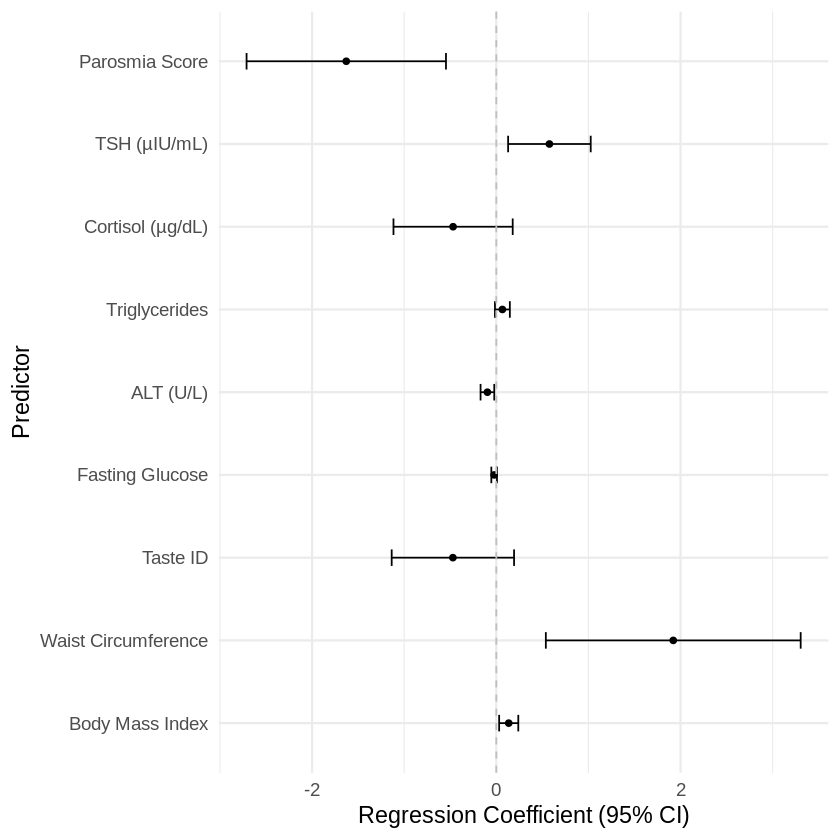

In [40]:
# 회귀모델
fit <- lm(sumVAS ~ BMI + waist_circum + tasteIdentification +
          fasting_glucose + ALT + triglyceride + cortisol + TSH + P,
          data = dataNew)

# 계수 테이블 추출
coefs <- tidy(fit, conf.int = TRUE)

# 변수 이름 정제
coefs$term <- factor(coefs$term, levels = rev(coefs$term))  # 역순 정렬

# 2. 변수명 매핑 테이블 만들기
name_map <- c(
  "BMI" = "Body Mass Index",
  "waist_circum" = "Waist Circumference",
  "tasteIdentification" = "Taste ID",
  "fasting_glucose" = "Fasting Glucose",
  "ALT" = "ALT (U/L)",
  "triglyceride" = "Triglycerides",
  "cortisol" = "Cortisol (µg/dL)",
  "TSH" = "TSH (µIU/mL)",
  "P" = "Parosmia Score"
)

# 3. 변수명 바꾸기 (Intercept는 그대로 두거나 제거)
coefs$term_clean <- ifelse(coefs$term %in% names(name_map),
                           name_map[coefs$term],
                           coefs$term)

# factor로 정렬 역순
coefs$term_clean <- factor(coefs$term_clean, levels = rev(unique(coefs$term_clean)))


ggplot(coefs[-1, ], aes(x = estimate, y = term_clean)) +  # Intercept 제외
  geom_point() +
  geom_errorbarh(aes(xmin = conf.low, xmax = conf.high), height = 0.2) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "gray") +
  xlab("Regression Coefficient (95% CI)") +
  ylab("Predictor") +
  theme_minimal(base_size = 14)

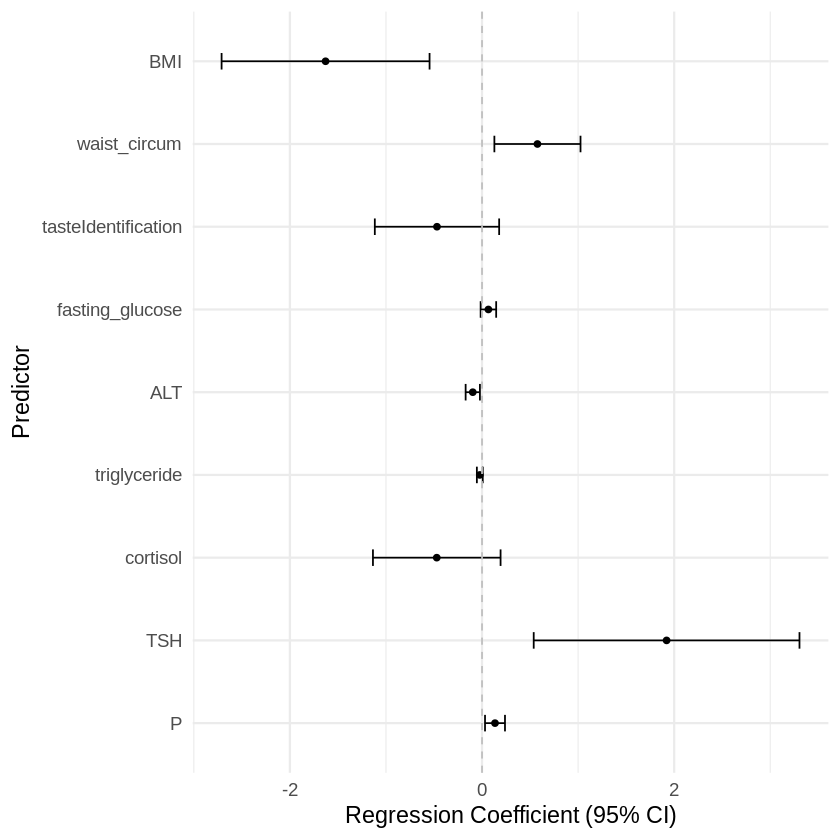

In [41]:
# 회귀모델
fit <- lm(sumVAS ~ BMI + waist_circum + tasteIdentification +
          fasting_glucose + ALT + triglyceride + cortisol + TSH + P,
          data = dataNew)

# 계수 테이블 추출
coefs <- tidy(fit, conf.int = TRUE)

# 변수 이름 정제
coefs$term <- factor(coefs$term, levels = rev(coefs$term))  # 역순 정렬

# Forest plot 그리기
ggplot(coefs[-1, ], aes(x = estimate, y = term)) +  # Intercept 제외
  geom_point() +
  geom_errorbarh(aes(xmin = conf.low, xmax = conf.high), height = 0.2) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "gray") +
  xlab("Regression Coefficient (95% CI)") +
  ylab("Predictor") +
  theme_minimal(base_size = 14)

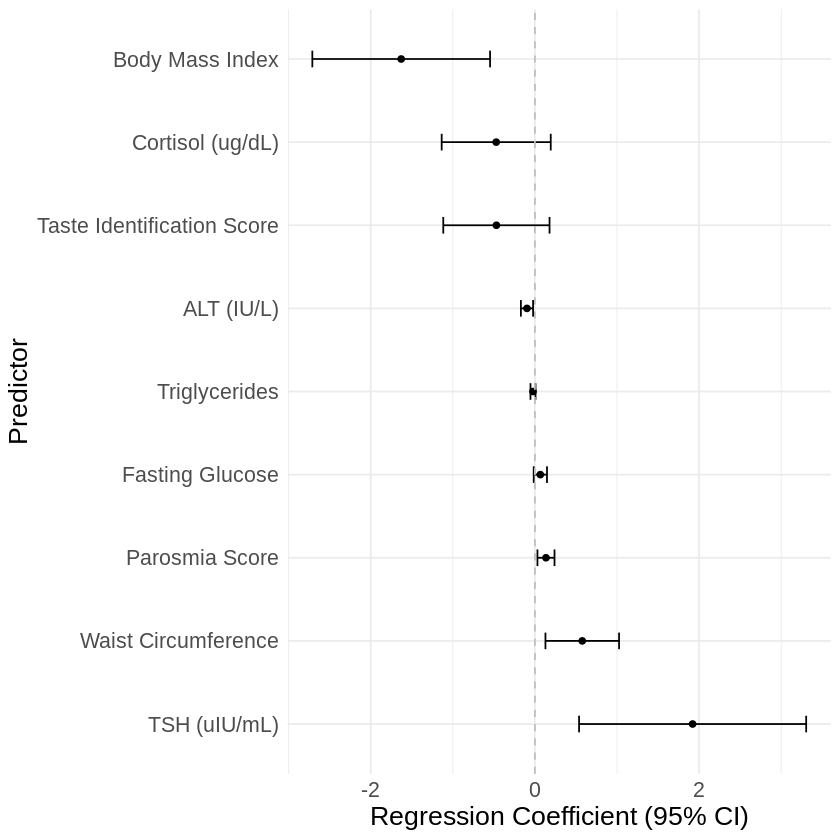

In [69]:
library(broom)
library(ggplot2)

# 회귀모델
fit <- lm(sumVAS ~ BMI + waist_circum + tasteIdentification +
          fasting_glucose + ALT + triglyceride + cortisol + TSH + P,
          data = dataNew)

# 계수 테이블 추출
coefs <- tidy(fit, conf.int = TRUE)

# Intercept 제거
coefs <- coefs[coefs$term != "(Intercept)", ]

# 2. 변수명 매핑 테이블 만들기
name_map <- c(
  "BMI" = "Body Mass Index",
  "waist_circum" = "Waist Circumference",
  "tasteIdentification" = "Taste Identification Score",
  "fasting_glucose" = "Fasting Glucose",
  "ALT" = "ALT (IU/L)",
  "triglyceride" = "Triglycerides",
  "cortisol" = "Cortisol (ug/dL)",
  "TSH" = "TSH (uIU/mL)",
  "P" = "Parosmia Score"
)

# 3. 변수명 바꾸기 (Intercept는 그대로 두거나 제거)
coefs$term_clean <- ifelse(coefs$term %in% names(name_map),
                           name_map[coefs$term],
                           coefs$term)

# term을 estimate 내림차순 기준으로 factor로 지정
coefs$term_clean <- factor(coefs$term_clean, levels = coefs$term_clean[order(-coefs$estimate)])

# Forest plot
library(ggplot2)
ggplot(coefs, aes(x = estimate, y = term_clean)) +
  geom_point() +
  geom_errorbarh(aes(xmin = conf.low, xmax = conf.high), height = 0.2) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "gray") + theme(axis.line = element_blank(),
#          panel.grid.major = element_blank(),
          panel.background = element_blank(),
          strip.background = element_blank(),
          axis.text.x = element_text(angle= 0, vjust = .5)) + theme_minimal() +
            theme(legend.position = "bottom", text = element_text(size = 16), plot.title = element_text(hjust = 0.5, size = 20) ) +
  xlab("Regression Coefficient (95% CI)") +
  ylab("Predictor")

In [70]:

png("Fig_reg1.png", width = 10, height = 7, units = 'in', res = 300)
ggplot(coefs, aes(x = estimate, y = term_clean)) +
  geom_point() +
  geom_errorbarh(aes(xmin = conf.low, xmax = conf.high), height = 0.2) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "gray") + theme(axis.line = element_blank(),
#          panel.grid.major = element_blank(),
          panel.background = element_blank(),
          strip.background = element_blank(),
          axis.text.x = element_text(angle= 0, vjust = .5)) + theme_minimal() +
            theme(legend.position = "bottom", text = element_text(size = 16), plot.title = element_text(hjust = 0.5, size = 20) ) +
  xlab("Regression Coefficient (95% CI)") +
  ylab("Predictor")
dev.off()

pdf 
  2

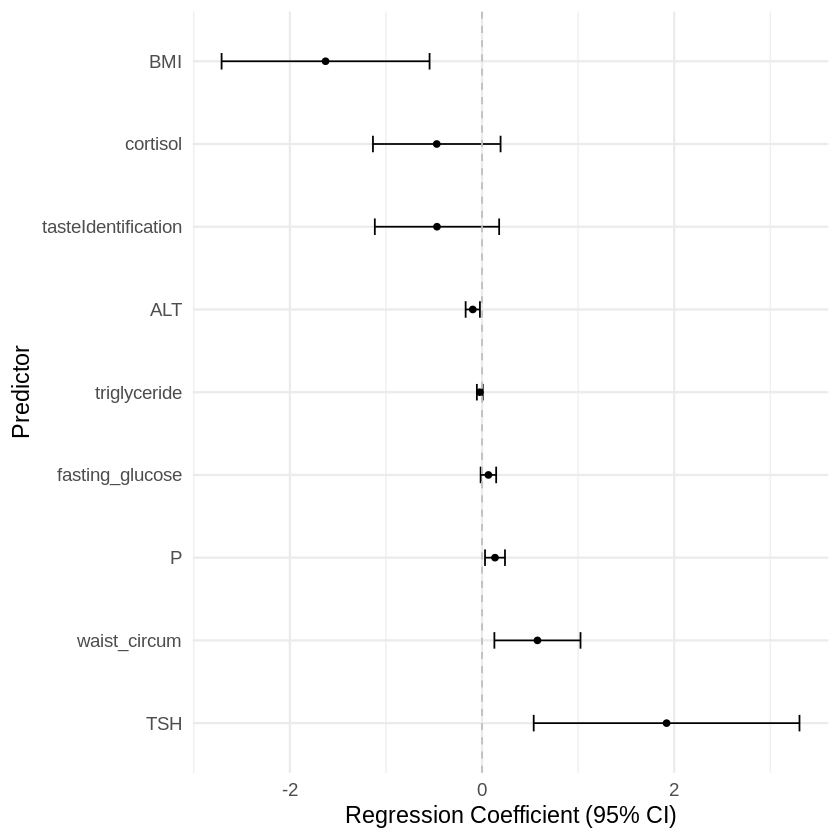

In [44]:

library(broom)
library(ggplot2)

# 회귀모델
fit <- lm(sumVAS ~ BMI + waist_circum + tasteIdentification +
          fasting_glucose + ALT + triglyceride + cortisol + TSH + P,
          data = dataNew)

# 계수 테이블 추출
coefs <- tidy(fit, conf.int = TRUE)

# Intercept 제거
coefs <- coefs[coefs$term != "(Intercept)", ]

# term을 estimate 내림차순 기준으로 factor로 지정
coefs$term <- factor(coefs$term, levels = coefs$term[order(-coefs$estimate)])

# Forest plot
library(ggplot2)
ggplot(coefs, aes(x = estimate, y = term)) +
  geom_point() +
  geom_errorbarh(aes(xmin = conf.low, xmax = conf.high), height = 0.2) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "gray") +
  xlab("Regression Coefficient (95% CI)") +
  ylab("Predictor") +
  theme_minimal(base_size = 14)

### TDI

In [48]:
dataNew3 <- na.omit(dataNew3)

model <- lm(TDI ~ .  , data = dataNew3[,-c(11:13,33)]) %>%
              stepAIC(trace = FALSE)
summary(model)


Call:
lm(formula = TDI ~ Age + BMI + SM + bodyfat + BMR + tasteIdentification + 
    WBC + `hs-CRP` + AST + ALT + T_cholesterol + HDLcholesterol + 
    LDLcholesterol, data = dataNew3[, -c(11:13, 33)])

Residuals:
    Min      1Q  Median      3Q     Max 
-3.3450 -0.9104  0.1914  0.9902  2.7989 

Coefficients:
                     Estimate Std. Error t value Pr(>|t|)    
(Intercept)          7.944303   7.160644   1.109 0.272157    
Age                 -0.078335   0.021247  -3.687 0.000528 ***
BMI                 -0.271415   0.133163  -2.038 0.046439 *  
SM                  -0.938998   0.596733  -1.574 0.121429    
bodyfat              0.215271   0.094192   2.285 0.026237 *  
BMR                  0.031972   0.015790   2.025 0.047846 *  
tasteIdentification  0.094913   0.060818   1.561 0.124458    
WBC                 -0.309886   0.116021  -2.671 0.009975 ** 
`hs-CRP`            -0.095376   0.065163  -1.464 0.149086    
AST                  0.015422   0.009059   1.702 0.094424 .  
ALT   

In [65]:
library(broom)
library(ggplot2)

# 회귀모델
fit <- lm(TDI ~ Age + BMI + bodyfat + BMR + tasteIdentification +
    WBC + `hs-CRP` + AST + ALT, data = dataNew3[, -c(11:13, 33)])

# 계수 테이블 추출
coefs <- tidy(fit, conf.int = TRUE)

# Intercept 제거
coefs <- coefs[coefs$term != "(Intercept)", ]


In [66]:
summary(fit)


Call:
lm(formula = TDI ~ Age + BMI + bodyfat + BMR + tasteIdentification + 
    WBC + `hs-CRP` + AST + ALT, data = dataNew3[, -c(11:13, 33)])

Residuals:
    Min      1Q  Median      3Q     Max 
-3.9872 -0.7650  0.0477  1.0284  2.6421 

Coefficients:
                     Estimate Std. Error t value Pr(>|t|)    
(Intercept)         17.895430   3.519244   5.085 4.13e-06 ***
Age                 -0.076968   0.020471  -3.760 0.000397 ***
BMI                 -0.356960   0.123158  -2.898 0.005286 ** 
bodyfat              0.289074   0.081430   3.550 0.000772 ***
BMR                  0.006763   0.002234   3.027 0.003681 ** 
tasteIdentification  0.111096   0.060774   1.828 0.072693 .  
WBC                 -0.233570   0.114604  -2.038 0.046112 *  
`hs-CRP`            -0.088738   0.065675  -1.351 0.181884    
AST                  0.016406   0.009278   1.768 0.082263 .  
ALT                 -0.022195   0.009105  -2.438 0.017876 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

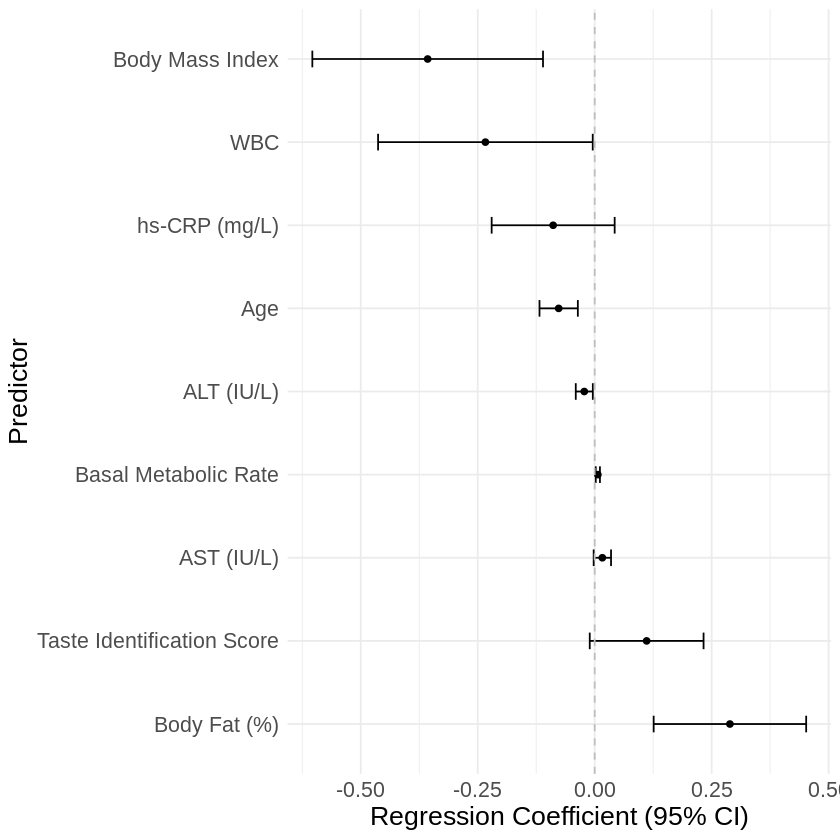

In [67]:


# 2. 변수명 매핑 테이블 만들기
name_map <- c(
  "BMI" = "Body Mass Index",
  "BMR" = "Basal Metabolic Rate",
  "bodyfat" = "Body Fat (%)",
  "waist_circum" = "Waist Circumference",
  "tasteIdentification" = "Taste Identification Score",
  "ALT" = "ALT (IU/L)",
  "AST" = "AST (IU/L)",
#  "SM" = "Skeletal Muscle Mass",
  "T_cholesterol" = "T Cholesterol",
  "HDLcholesterol" = "HDL cholesterol",
  "LDLcholesterol" = "LDL cholesterol",
  "`hs-CRP`" = "hs-CRP (mg/L)",
  "P" = "Parosmia Score"
)

# 3. 변수명 바꾸기 (Intercept는 그대로 두거나 제거)
coefs$term_clean <- ifelse(coefs$term %in% names(name_map),
                           name_map[coefs$term],
                           coefs$term)

# term을 estimate 내림차순 기준으로 factor로 지정
coefs$term_clean <- factor(coefs$term_clean, levels = coefs$term_clean[order(-coefs$estimate)])

# Forest plot
library(ggplot2)
ggplot(coefs, aes(x = estimate, y = term_clean)) +
  geom_point() +
  geom_errorbarh(aes(xmin = conf.low, xmax = conf.high), height = 0.2) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "gray") + theme(axis.line = element_blank(),
#          panel.grid.major = element_blank(),
          panel.background = element_blank(),
          strip.background = element_blank(),
          axis.text.x = element_text(angle= 0, vjust = .5)) + theme_minimal() +
            theme(legend.position = "bottom", text = element_text(size = 16), plot.title = element_text(hjust = 0.5, size = 20) ) +
  xlab("Regression Coefficient (95% CI)") +
  ylab("Predictor")

In [68]:

png("Fig_reg2.png", width = 10, height = 7, units = 'in', res = 300)
ggplot(coefs, aes(x = estimate, y = term_clean)) +
  geom_point() +
  geom_errorbarh(aes(xmin = conf.low, xmax = conf.high), height = 0.2) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "gray") + theme(axis.line = element_blank(),
#          panel.grid.major = element_blank(),
          panel.background = element_blank(),
          strip.background = element_blank(),
          axis.text.x = element_text(angle= 0, vjust = .5)) + theme_minimal() +
            theme(legend.position = "bottom", text = element_text(size = 16), plot.title = element_text(hjust = 0.5, size = 20) ) +
  xlab("Regression Coefficient (95% CI)") +
  ylab("Predictor")
dev.off()

pdf 
  2

### Parosmia

In [71]:
model <- lm(P ~ .  , data = dataNew3[,-c(11:13,33)]) %>%
              stepAIC(trace = FALSE)
summary(model)


Call:
lm(formula = P ~ weight + BMI + SM + BMR + uric_acid + ALT + 
    insulin + TSH + sumVAS, data = dataNew3[, -c(11:13, 33)])

Residuals:
    Min      1Q  Median      3Q     Max 
-31.361 -12.089   0.404  10.382  44.376 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)  
(Intercept) -263.92072  126.66500  -2.084   0.0416 *
weight        -1.85871    0.76996  -2.414   0.0190 *
BMI            3.89438    1.50279   2.591   0.0121 *
SM           -16.76641    8.16839  -2.053   0.0446 *
BMR            0.55382    0.25083   2.208   0.0312 *
uric_acid     -4.44980    2.06861  -2.151   0.0356 *
ALT            0.16319    0.08388   1.945   0.0566 .
insulin       -0.11102    0.06760  -1.642   0.1059  
TSH           -2.18147    1.62540  -1.342   0.1848  
sumVAS         0.61759    0.25818   2.392   0.0200 *
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 17.81 on 58 degrees of freedom
Multiple R-squared:  0.2974,	Adjusted R-squared:  0.1

In [76]:
R.version


               _                           
platform       x86_64-pc-linux-gnu         
arch           x86_64                      
os             linux-gnu                   
system         x86_64, linux-gnu           
status                                     
major          4                           
minor          5.1                         
year           2025                        
month          06                          
day            13                          
svn rev        88306                       
language       R                           
version.string R version 4.5.1 (2025-06-13)
nickname       Great Square Root           

In [73]:
library(broom)
library(ggplot2)

# 회귀모델
fit <- lm(P ~ weight + BMI + SM + BMR + uric_acid + ALT +
    insulin + TSH + sumVAS, data = dataNew3[, -c(11:13, 33)])

# 계수 테이블 추출
coefs <- tidy(fit, conf.int = TRUE)

# Intercept 제거
coefs <- coefs[coefs$term != "(Intercept)", ]

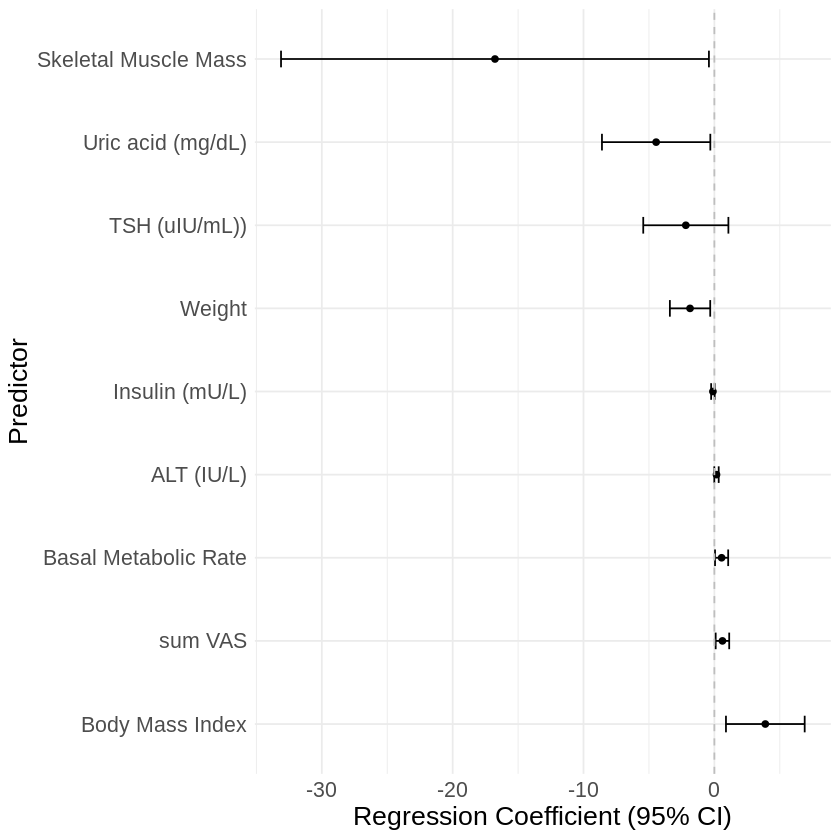

In [74]:

# 2. 변수명 매핑 테이블 만들기
name_map <- c(
  "weight" = "Weight",
  "BMI" = "Body Mass Index",
  "BMR" = "Basal Metabolic Rate",
  "SM" = "Skeletal Muscle Mass",
  "uric_acid" = "Uric acid (mg/dL)",
  "ALT" = "ALT (IU/L)",
  "insulin" = "Insulin (mU/L)",
  "TSH" = "TSH (uIU/mL))",
  "sumVAS" = "sum VAS"
)

# 3. 변수명 바꾸기 (Intercept는 그대로 두거나 제거)
coefs$term_clean <- ifelse(coefs$term %in% names(name_map),
                           name_map[coefs$term],
                           coefs$term)

# term을 estimate 내림차순 기준으로 factor로 지정
coefs$term_clean <- factor(coefs$term_clean, levels = coefs$term_clean[order(-coefs$estimate)])

# Forest plot
library(ggplot2)
ggplot(coefs, aes(x = estimate, y = term_clean)) +
  geom_point() +
  geom_errorbarh(aes(xmin = conf.low, xmax = conf.high), height = 0.2) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "gray") + theme(axis.line = element_blank(),
#          panel.grid.major = element_blank(),
          panel.background = element_blank(),
          strip.background = element_blank(),
          axis.text.x = element_text(angle= 0, vjust = .5)) + theme_minimal() +
            theme(legend.position = "bottom", text = element_text(size = 16), plot.title = element_text(hjust = 0.5, size = 20) ) +
  xlab("Regression Coefficient (95% CI)") +
  ylab("Predictor")

In [75]:

png("Fig_reg3.png", width = 10, height = 7, units = 'in', res = 300)
ggplot(coefs, aes(x = estimate, y = term_clean)) +
  geom_point() +
  geom_errorbarh(aes(xmin = conf.low, xmax = conf.high), height = 0.2) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "gray") + theme(axis.line = element_blank(),
#          panel.grid.major = element_blank(),
          panel.background = element_blank(),
          strip.background = element_blank(),
          axis.text.x = element_text(angle= 0, vjust = .5)) + theme_minimal() +
            theme(legend.position = "bottom", text = element_text(size = 16), plot.title = element_text(hjust = 0.5, size = 20) ) +
  xlab("Regression Coefficient (95% CI)") +
  ylab("Predictor")
dev.off()

pdf 
  2

In [46]:
library(MASS)
model <- lm(sumVAS ~ .  , data = dataNew) %>%
              stepAIC(trace = FALSE)
summary(model)

model <- lm(TDI ~ Sex + Age + Smoking + Height + weight + BMI + SM + bodyfat + BMR + waist_circum + WBC + 'hs-CRP' + fasting_glucose + uric_acid + AST + ALT + insulin + T_cholesterol + triglyceride + HDLcholesterol + LDLcholesterol + cortisol + freeT4 + TSH +P + sumVAS  , data = dataNew3) %>%
              stepAIC(trace = FALSE)
summary(model)


Call:
lm(formula = sumVAS ~ BMI + waist_circum + tasteIdentification + 
    fasting_glucose + ALT + triglyceride + cortisol + TSH + P, 
    data = dataNew)

Residuals:
    Min      1Q  Median      3Q     Max 
-13.222  -5.914  -1.195   4.599  24.921 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)   
(Intercept)          2.22965   12.43379   0.179  0.85831   
BMI                 -1.62863    0.54072  -3.012  0.00384 **
waist_circum         0.57674    0.22396   2.575  0.01259 * 
tasteIdentification -0.46900    0.32328  -1.451  0.15223   
fasting_glucose      0.06624    0.04040   1.640  0.10650   
ALT                 -0.09642    0.03713  -2.597  0.01190 * 
triglyceride        -0.02313    0.01533  -1.508  0.13690   
cortisol            -0.47132    0.33183  -1.420  0.16086   
TSH                  1.92105    0.69102   2.780  0.00732 **
P                    0.13493    0.05191   2.599  0.01183 * 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residu

Warning message:
“attempting model selection on an essentially perfect fit is nonsense”
Warning message:
“attempting model selection on an essentially perfect fit is nonsense”
Warning message:
“attempting model selection on an essentially perfect fit is nonsense”
Warning message:
“attempting model selection on an essentially perfect fit is nonsense”
Warning message:
“attempting model selection on an essentially perfect fit is nonsense”
Warning message:
“attempting model selection on an essentially perfect fit is nonsense”


ERROR: Error in stepAIC(., trace = FALSE): number of rows in use has changed: remove missing values?


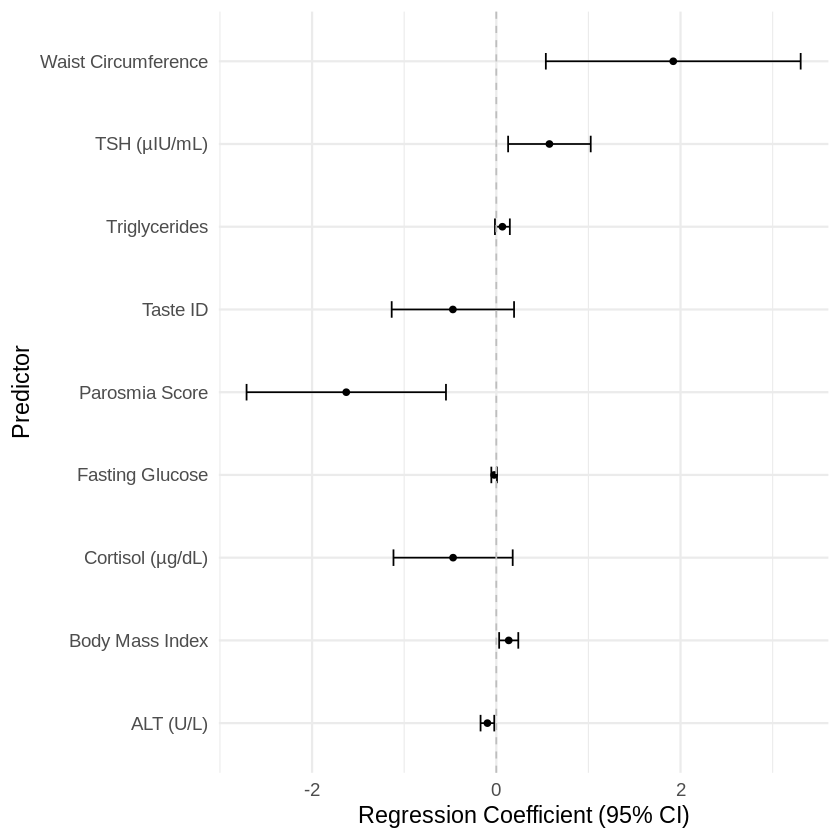

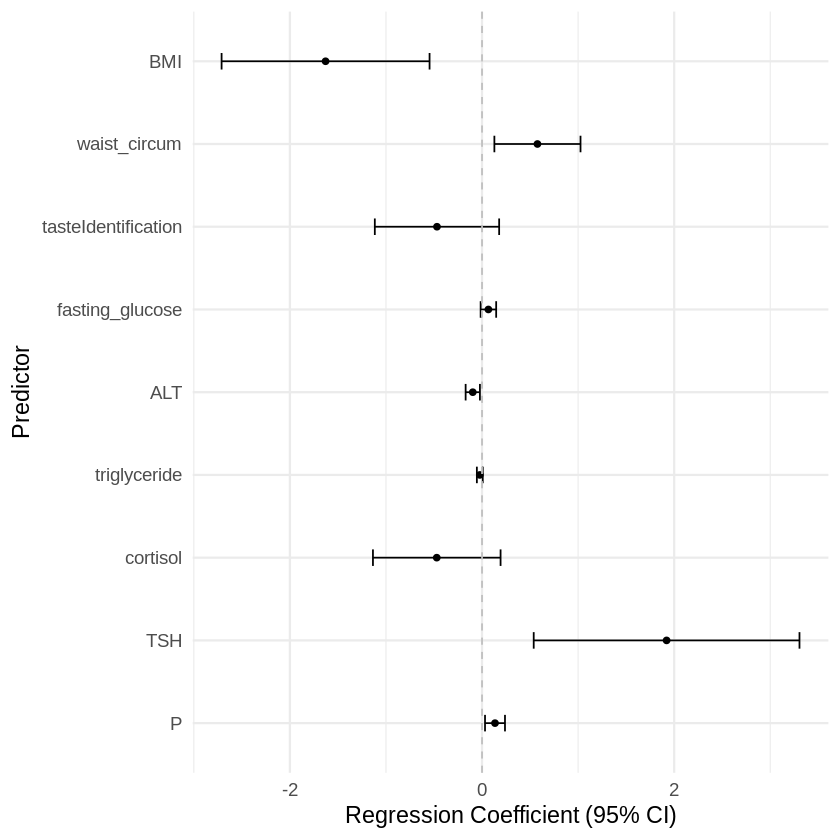

In [45]:

# 회귀모델
fit <- lm(sumVAS ~ BMI + waist_circum + tasteIdentification +
          fasting_glucose + ALT + triglyceride + cortisol + TSH + P,
          data = dataNew)

# 계수 테이블 추출
coefs <- tidy(fit, conf.int = TRUE)

# 변수 이름 정제
coefs$term <- factor(coefs$term, levels = rev(coefs$term))  # 역순 정렬

# 2. 변수명 매핑 테이블 만들기
name_map <- c(
  "BMI" = "Body Mass Index",
  "waist_circum" = "Waist Circumference",
  "tasteIdentification" = "Taste ID",
  "fasting_glucose" = "Fasting Glucose",
  "ALT" = "ALT (U/L)",
  "triglyceride" = "Triglycerides",
  "cortisol" = "Cortisol (µg/dL)",
  "TSH" = "TSH (µIU/mL)",
  "P" = "Parosmia Score"
)

# 3. 변수명 바꾸기 (Intercept는 그대로 두거나 제거)
coefs$term_clean <- ifelse(coefs$term %in% names(name_map),
                           name_map[coefs$term],
                           coefs$term)

# factor로 정렬 역순
#coefs$term_clean <- factor(coefs$term_clean, levels = rev(unique(coefs$term_clean)))


ggplot(coefs[-1, ], aes(x = estimate, y = term_clean)) +  # Intercept 제외
  geom_point() +
  geom_errorbarh(aes(xmin = conf.low, xmax = conf.high), height = 0.2) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "gray") +
  xlab("Regression Coefficient (95% CI)") +
  ylab("Predictor") +
  theme_minimal(base_size = 14)

# Forest plot 그리기
ggplot(coefs[-1, ], aes(x = estimate, y = term)) +  # Intercept 제외
  geom_point() +
  geom_errorbarh(aes(xmin = conf.low, xmax = conf.high), height = 0.2) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "gray") +
  xlab("Regression Coefficient (95% CI)") +
  ylab("Predictor") +
  theme_minimal(base_size = 14)

In [ ]:
# prompt: sumVAS, BMI, waist_circum, tasteIdentification, fasting_glucose , ALT , triglyceride, cortisol , TSH, P 들간의 상관관계 출력

correlation_data <- data[, c('sumVAS', 'BMI', 'waist_circum', 'tasteIdentification', 'fasting_glucose', 'ALT', 'triglyceride', 'cortisol', 'TSH', 'P')]
correlation_matrix <- cor(correlation_data, use = "pairwise.complete.obs")
correlation_matrix

,sumVAS,BMI,waist_circum,tasteIdentification,fasting_glucose,ALT,triglyceride,cortisol,TSH,P
sumVAS,1.00000000,-0.18500170,-0.14340422,-0.059750379,0.03885790,-0.19761660,-0.11739978,-0.03925578,0.217090582,0.317874730
BMI,-0.18500170,1.00000000,0.93814990,-0.090610121,0.12181205,0.23573024,0.24761599,-0.16550038,0.129389817,-0.077540331
waist_circum,-0.14340422,0.93814990,1.00000000,-0.122162832,0.07814746,0.30442912,0.35270243,-0.18153024,0.060609880,-0.123570276
tasteIdentification,-0.05975038,-0.09061012,-0.12216283,1.000000000,-0.02237317,-0.16931305,-0.16105388,-0.12896906,0.004527335,-0.004462276
fasting_glucose,0.03885790,0.12181205,0.07814746,-0.022373167,1.00000000,0.24618276,0.14418050,-0.02239580,-0.136430624,0.170190778
ALT,-0.19761660,0.23573024,0.30442912,-0.169313049,0.24618276,1.00000000,0.20778340,-0.08380873,0.048264811,-0.020634259
triglyceride,-0.11739978,0.24761599,0.35270243,-0.161053884,0.14418050,0.20778340,1.00000000,-0.18640055,-0.077551228,0.010966357
cortisol,-0.03925578,-0.16550038,-0.18153024,-0.128969058,-0.02239580,-0.08380873,-0.18640055,1.00000000,0.083979402,-0.012548788
TSH,0.21709058,0.12938982,0.06060988,0.004527335,-0.13643062,0.04826481,-0.07755123,0.08397940,1.000000000,0.021108770
P,0.31787473,-0.07754033,-0.12357028,-0.004462276,0.17019078,-0.02063426,0.01096636,-0.01254879,0.021108770,1.000000000


In [ ]:
library(MASS)
model <- lm(sumVAS ~ BMI  , data = dataNew)
summary(model)


Attaching package: ‘MASS’


The following object is masked from ‘package:dplyr’:

    select





Call:
lm(formula = sumVAS ~ BMI, data = dataNew)

Residuals:
   Min     1Q Median     3Q    Max 
-8.696 -5.669 -3.069  0.999 38.221 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)  
(Intercept)  14.7498     5.8372   2.527   0.0139 *
BMI          -0.3137     0.1899  -1.652   0.1033  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 9.047 on 66 degrees of freedom
Multiple R-squared:  0.0397,	Adjusted R-squared:  0.02515 
F-statistic: 2.729 on 1 and 66 DF,  p-value: 0.1033


In [ ]:
colSums(is.na(data))

id_num                 ENTdate                 reginum 
                      0                       0                       0 
                   weak                     Sex                     Age 
                     47                       0                       0 
                Smoking                  Height                  weight 
                      0                       0                       0 
                    BMI                      SM                 bodyfat 
                      0                       0                       0 
                    BMR            waist_circum               Threshold 
                      0                       0                       0 
         Discrimination          Identification                     TDI 
                      0                       0                       0 
         tasteThreshold     tasteIdentification                     WBC 
                      0                       0                       0 
                 hs-CRP         fasting_glucose               uric_acid 
                      1                       0                       1 
                    AST                     ALT                 insulin 
                      0                       0                       0 
          T_cholesterol            triglyceride          HDLcholesterol 
                      0                       0                       0 
         LDLcholesterol                cortisol                  freeT4 
                      0                       0                       0 
                    TSH              medication                     etc 
                      0                       0                      70 
                  a1-LQ                   a4-LQ                  a11-LQ 
                      0                       0                       0 
                 a13-LQ                  a15-LQ                  a19-LQ 
                      0                       0                       0 
                 a22-LQ                  a26-LQ                  a27-LQ 
                      0                       0                       0 
                 a28-LQ                  a33-LQ                  a34-LQ 
                      0                       0                       0 
                 a37-LQ                  a39-LQ                  a42-LQ 
                      0                       0                       0 
                 a49-LQ                  a50-LQ                  a32-LQ 
                      0                       0                       0 
                 a35-LQ               sumQOD-LQ                      LQ 
                      0                       0                       0 
                  a14-S                   a17-S                   a23-S 
                      0                       0                       0 
                  a31-S                   a36-S                   a48-S 
                      0                       0                       0 
               sumQOD-S                       S                    a1-P 
                      0                       0                       0 
                   a2-P                    a3-P                    a5-P 
                      0                       0                       0 
               sumQOD-P                       P                  sumVAS 
                      0                       0                       0 
          nose_function          taste_function  Phentermine_Naltrexone 
                      0                       0                       1 
               Orlistat Liraglutide_Semaglutide            BMI_category 
                      0                       0                       0 
          BMI_category2           BMI_category3         subjective_nose 
                      0                       0                       0

### 4. VAS 와 TDI 상관관계 없었음

->질문은 TDI (후각 정상 vs 후각 이상으로 나누지 말고) score 들과 유의하게 연관성을 보이는 인자들이 있는지?

TDI 점수, Threshold 점수, Discrimination 점수, Identification 점수 자체와 positive or negative 연관성 보이는 인자가 있는지 추가 분석 부탁드립니다.

### TDI 점수 등등을 Y 로 두고 multivariate regression 적합

In [ ]:
dataNew3 <- na.omit(dataNew3)

In [ ]:
colnames(dataNew3)

[1] "Sex"                 "Age"                 "Smoking"            
 [4] "Height"              "weight"              "BMI"                
 [7] "SM"                  "bodyfat"             "BMR"                
[10] "waist_circum"        "Threshold"           "Discrimination"     
[13] "Identification"      "TDI"                 "tasteThreshold"     
[16] "tasteIdentification" "WBC"                 "hs-CRP"             
[19] "fasting_glucose"     "uric_acid"           "AST"                
[22] "ALT"                 "insulin"             "T_cholesterol"      
[25] "triglyceride"        "HDLcholesterol"      "LDLcholesterol"     
[28] "cortisol"            "freeT4"              "TSH"                
[31] "P"                   "sumVAS"              "nose_function"

In [ ]:
colnames(dataNew3)[-c(11:13)]

[1] "Sex"                 "Age"                 "Smoking"            
 [4] "Height"              "weight"              "BMI"                
 [7] "SM"                  "bodyfat"             "BMR"                
[10] "waist_circum"        "TDI"                 "tasteThreshold"     
[13] "tasteIdentification" "WBC"                 "hs-CRP"             
[16] "fasting_glucose"     "uric_acid"           "AST"                
[19] "ALT"                 "insulin"             "T_cholesterol"      
[22] "triglyceride"        "HDLcholesterol"      "LDLcholesterol"     
[25] "cortisol"            "freeT4"              "TSH"                
[28] "P"                   "sumVAS"              "nose_function"

In [ ]:
model <- lm(P ~ .  , data = dataNew3[,-c(11:13,33)]) %>%
              stepAIC(trace = FALSE)
summary(model)


Call:
lm(formula = P ~ weight + BMI + SM + BMR + uric_acid + ALT + 
    insulin + TSH + sumVAS, data = dataNew3[, -c(11:13, 33)])

Residuals:
    Min      1Q  Median      3Q     Max 
-31.361 -12.089   0.404  10.382  44.376 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)  
(Intercept) -263.92072  126.66500  -2.084   0.0416 *
weight        -1.85871    0.76996  -2.414   0.0190 *
BMI            3.89438    1.50279   2.591   0.0121 *
SM           -16.76641    8.16839  -2.053   0.0446 *
BMR            0.55382    0.25083   2.208   0.0312 *
uric_acid     -4.44980    2.06861  -2.151   0.0356 *
ALT            0.16319    0.08388   1.945   0.0566 .
insulin       -0.11102    0.06760  -1.642   0.1059  
TSH           -2.18147    1.62540  -1.342   0.1848  
sumVAS         0.61759    0.25818   2.392   0.0200 *
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 17.81 on 58 degrees of freedom
Multiple R-squared:  0.2974,	Adjusted R-squared:  0.1

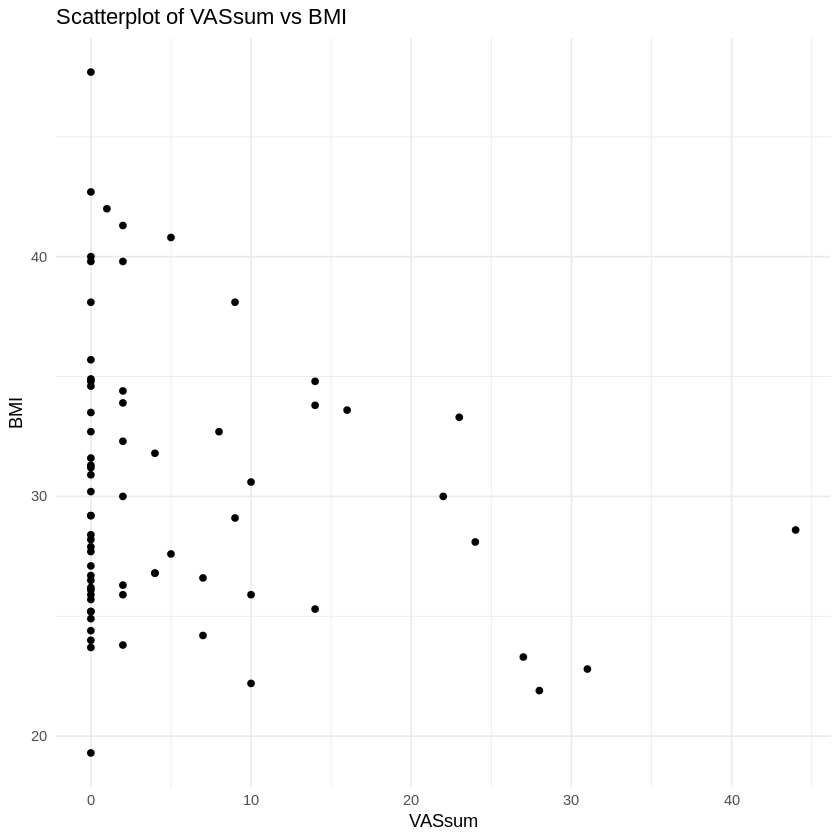

In [ ]:
# prompt: VASsum 과 BMI 의 상관관계 그려줘

ggplot(data, aes(x = sumVAS, y = BMI)) +
  geom_point() +
  labs(x = "VASsum", y = "BMI", title = "Scatterplot of VASsum vs BMI") +
  theme_minimal()

#### TDI score 모델링

In [ ]:
colnames(dataNew3)[33]

[1] "nose_function"

In [ ]:
model <- lm(TDI ~ .  , data = dataNew3[,-c(11:13,33)]) %>%
              stepAIC(trace = FALSE)
summary(model)

ERROR: Error in stepAIC(., trace = FALSE): number of rows in use has changed: remove missing values?


In [ ]:
model <- lm(Threshold ~ .  , data = dataNew3[,-c(12:14,33)]) %>%
              stepAIC(trace = FALSE)
summary(model)


Call:
lm(formula = Threshold ~ weight + SM + bodyfat + tasteIdentification + 
    WBC + uric_acid + AST + P, data = dataNew3[, -c(12:14, 33)])

Residuals:
     Min       1Q   Median       3Q      Max 
-1.81068 -0.47780 -0.06957  0.58190  1.74371 

Coefficients:
                     Estimate Std. Error t value Pr(>|t|)    
(Intercept)          8.250455   2.487111   3.317 0.001560 ** 
weight               0.078530   0.045702   1.718 0.090983 .  
SM                  -0.196663   0.128691  -1.528 0.131812    
bodyfat             -0.118520   0.067294  -1.761 0.083383 .  
tasteIdentification  0.087668   0.033396   2.625 0.011015 *  
WBC                 -0.146564   0.064222  -2.282 0.026102 *  
uric_acid           -0.268738   0.103725  -2.591 0.012045 *  
AST                  0.013901   0.003979   3.493 0.000912 ***
P                   -0.017613   0.005640  -3.123 0.002773 ** 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.8534 on 59 degrees of 

In [ ]:
model <- lm(Discrimination ~ .  , data = dataNew3[,-c(11,13,14,33)]) %>%
              stepAIC(trace = FALSE)
summary(model)

In [ ]:
model <- lm(Identification ~ .  , data = dataNew3[,-c(11,12,14,33)]) %>%
              stepAIC(trace = FALSE)
summary(model)

In [ ]:
colnames(dataNew3)

In [ ]:
model <- lm(tasteIdentification ~ .  , data = dataNew3[,-c(15,33)]) %>%
              stepAIC(trace = FALSE)
summary(model)

In [ ]:

model <- lm(tasteThreshold ~ .  , data = dataNew3[,-c(16,33)]) %>%
              stepAIC(trace = FALSE)
summary(model)

In [ ]:
model <- lm(TDI ~ Sex + Age + Smoking + Height + weight + BMI + SM + bodyfat + BMR + waist_circum + WBC + 'hs-CRP' + fasting_glucose + uric_acid + AST + ALT + insulin + T_cholesterol + triglyceride + HDLcholesterol + LDLcholesterol + cortisol + freeT4 + TSH +P + sumVAS  , data = dataNew3) %>%
              stepAIC(trace = FALSE)
summary(model)

In [ ]:
# prompt: nose_function 을 y로 해서 logistic regression 적합

# nose_function을 y로 한 logistic regression 적합
# nose_function은 범주형 변수인지 확인 필요 (0 또는 1로 코딩되어 있다고 가정)
# 만약 연속형이라면 linear regression 사용

# nose_function 변수 확인 (0 또는 1로 되어있어야 함)
# unique(data$nose_function)

# 로지스틱 회귀 모델 적합
# nose_function ~ 나머지 변수들 (종속 변수와 독립 변수를 적절히 선택)
# 여기서는 모든 다른 변수를 독립 변수로 사용한다고 가정
# 종속 변수가 nose_function이고 독립 변수가 다른 모든 변수라고 가정
# 모델 적합 시 NA 값 처리가 필요할 수 있습니다.
model_logistic <- glm(nose_function ~ ., data = data[, -which(names(data) == "nose_function")], family = binomial)

# 모델 요약
summary(model_logistic)

# 필요한 경우 후진 제거법 또는 다른 변수 선택 방법 사용
# step_logistic <- step(model_logistic, direction = "backward")
# summary(step_logistic)


In [ ]:
dataNew2 <- na.omit(dataNew2)

dim(dataNew2)

In [ ]:
colnames(data)[14]

BMI group에 따라
1. 후각검사 상의 thredhold  discrimination  identification
2. 미각검사 상의 detectoon threshold, recognition threshold
3. 주관적 설문지 결과에 차이가 있는지 추가 분석 부탁드려도 될지요?



In [ ]:
mytable(nose_function ~ BMI + BMI_category + BMI_category2 , data=data, digits=2, catMethod=0)

In [ ]:
colnames(data)

In [ ]:
mytable(BMI_category ~  Threshold + Discrimination + Identification + TDI + tasteThreshold + tasteIdentification + nose_function, data=data, digits=2, catMethod=0)

In [ ]:
mytable(BMI_category2 ~  Threshold + Discrimination + Identification + TDI + tasteThreshold + tasteIdentification + nose_function, data=data, digits=2, catMethod=0)

In [ ]:
mytable(BMI_category3 ~  Threshold + Discrimination + Identification + TDI + tasteThreshold + tasteIdentification + nose_function, data=data, digits=2, catMethod=0)

BMI 25 기준으로 나누면 thrshold 에서는 차이가 있음

지난번 BMI(체질량지수)로 그룹핑하여 분석 부탁드렸는데요.

비만의 다른 진단지표로 요청드리려고 합니다.

(BMI 외에 비만을 진단하는 지표는 체지방률(%), 허리둘레(cm)가 있습니다.)

- 체지방률: 남성 25%, 여성 30% 이상 시 비만

- 허리둘레(cm): 남성 90, 여성 85 이상 시 복부비만



제가 엑셀파일 내

- CE열: 체지방률을 기준으로 비만인 경우 1, 아닌 경우 0 (총 70명 중 비만인 대상자 5명)

- CF열: 허리둘레를 기준으로 비만인 경우 1, 아닌 경우 0 (총 70명 중 비만인 대상자 11명)으로 코딩하였습니다.



체지방률을 기준으로 한 비만의 경우 n수가 적어 의미가 없을 것으로 보입니다.

'허리둘레를 기준으로 한 비만 여부'에 따라, 이전 분석들을 부탁드려도 될지요?

( 1. 후각검사 상의 thredhold  discrimination  identification

2. 미각검사 상의 detectoon threshold, recognition threshold

3. 주관적 설문지 결과에 차이가 있는지)



In [ ]:
mytable(Obesity_wc ~  Threshold + Discrimination + Identification + TDI + tasteThreshold + tasteIdentification + nose_function, data=data, digits=2, catMethod=0)


       Descriptive Statistics by 'Obesity_wc'      
———————————————————————————————————————————————————— 
                          0            1         p  
                        (N=12)       (N=58)   
———————————————————————————————————————————————————— 
 Threshold           4.25 ± 0.87  3.86 ± 1.07  0.244
 Discrimination      8.50 ± 0.52  9.07 ± 1.51  0.026
 Identification                                0.870
   - 9                 0 ( 0.0%)   1 (1.72%)        
   - 10                0 ( 0.0%)   3 (5.17%)        
   - 11               2 (16.67%)  13 (22.41%)       
   - 12              10 (83.33%)  41 (70.69%)       
 TDI                 24.58 ± 0.85 24.55 ± 2.09 0.932
 tasteThreshold                                1.000
   - 4                 0 ( 0.0%)   2 (3.45%)        
   - 5                5 (41.67%)  25 (43.10%)       
   - 6                7 (58.33%)  31 (53.45%)       
 tasteIdentification 19.00 ± 3.72 17.84 ± 3.16 0.267
 nose_function                                 0.5

In [ ]:
mytable(Obesity_bf ~  Threshold + Discrimination + Identification + TDI + tasteThreshold + tasteIdentification + nose_function, data=data, digits=2, catMethod=0)


       Descriptive Statistics by 'Obesity_bf'      
———————————————————————————————————————————————————— 
                          0            1         p  
                        (N=5)        (N=65)   
———————————————————————————————————————————————————— 
 Threshold           4.50 ± 0.87  3.88 ± 1.05  0.206
 Discrimination      8.40 ± 0.55  9.02 ± 1.44  0.349
 Identification                                1.000
   - 9                 0 ( 0.0%)   1 (1.54%)        
   - 10                0 ( 0.0%)   3 (4.62%)        
   - 11               1 (20.00%)  14 (21.54%)       
   - 12               4 (80.00%)  47 (72.31%)       
 TDI                 24.70 ± 0.45 24.55 ± 2.00 0.633
 tasteThreshold                                0.278
   - 4                 0 ( 0.0%)   2 (3.08%)        
   - 5                4 (80.00%)  26 (40.00%)       
   - 6                1 (20.00%)  37 (56.92%)       
 tasteIdentification 18.40 ± 2.97 18.02 ± 3.30 0.801
 nose_function                                 1.0

In [ ]:
CreateTableOne(vars = c("Threshold", "Discrimination", "Identification", "TDI", "tasteThreshold", "tasteIdentification"), strata = "Obesity_wc", data = data)

                                 Stratified by Obesity_wc
                                  0            1            p      test
  n                                  12           58                   
  Threshold (mean (SD))            4.25 (0.87)  3.86 (1.07)  0.244     
  Discrimination (mean (SD))       8.50 (0.52)  9.07 (1.51)  0.203     
  Identification (mean (SD))      11.83 (0.39) 11.62 (0.67)  0.294     
  TDI (mean (SD))                 24.58 (0.85) 24.55 (2.09)  0.959     
  tasteThreshold (mean (SD))       5.58 (0.51)  5.50 (0.57)  0.641     
  tasteIdentification (mean (SD)) 19.00 (3.72) 17.84 (3.16)  0.267     

In [ ]:
CreateTableOne(vars = c("Threshold", "Discrimination", "Identification", "TDI", "tasteThreshold", "tasteIdentification"), strata = "Obesity_bf", data = data)

                                 Stratified by Obesity_bf
                                  0            1            p      test
  n                                   5           65                   
  Threshold (mean (SD))            4.50 (0.87)  3.88 (1.05)  0.206     
  Discrimination (mean (SD))       8.40 (0.55)  9.02 (1.44)  0.349     
  Identification (mean (SD))      11.80 (0.45) 11.65 (0.65)  0.605     
  TDI (mean (SD))                 24.70 (0.45) 24.55 (2.00)  0.865     
  tasteThreshold (mean (SD))       5.20 (0.45)  5.54 (0.56)  0.193     
  tasteIdentification (mean (SD)) 18.40 (2.97) 18.02 (3.30)  0.801     

In [ ]:
Obesity_wc